#Evaluación automática de daños vehiculares con Deep Learning

Objetivo: entrenar una red neuronal convolucional que, a partir de una foto de un vehículo siniestrado,
clasifique la **severidad del daño** (leve / moderado / grave). Esa predicción alimenta un módulo de
estimación de costos y de decisión para una aseguradora, desplegado en AWS.

**Enfoque:** *transfer learning* con **EfficientNetB0** preentrenada en ImageNet, en dos fases:
1. **Extracción de características:** se congela la red base y solo se entrena la "cabeza" nueva.
2. **Fine-tuning:** se descongelan las últimas capas de la red base y se reentrenan con una tasa de aprendizaje muy baja.


## 0. Configuración

In [ ]:

DATASET_KAGGLE = "prajwalbhamere/car-damage-severity-dataset"  # dataset de Kaggle (minor / moderate / severe)
IMG_SIZE = 224          # tamaño de entrada de EfficientNetB0
BATCH = 32
SEED = 42
EPOCAS_FASE1 = 15       # entrenamiento de la cabeza (EarlyStopping corta antes si deja de mejorar)
EPOCAS_FASE2 = 15       # fine-tuning
CAPAS_A_DESCONGELAR = 60
PESOS = "imagenet"      # pesos preentrenados
EXCLUIR_CLASES = set()  # ej: {"whole"} si el dataset trae una carpeta que no quieres usar
USAR_CASOS_REVISADOS = False  # True para sumar los casos confirmados por liquidadores (zip exportado desde la bandeja)
VERSION_MODELO = "efficientnetb0-v2"  # súbela (v3, v4...) cada vez que reentrenes con datos nuevos
EPOCAS_CNN_PROPIA = 25  # sección 10: CNN propia con convolución y pooling (comparación)

In [ ]:
import os, re, json, hashlib, pathlib, random, zipfile
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU") or "NO (activa la GPU en Colab)")

TensorFlow 2.21.0 | Keras 3.13.2
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Descarga del dataset


In [ ]:
USAR_ZIP_PROPIO = False

if USAR_ZIP_PROPIO:
    from google.colab import files
    subido = files.upload()
    nombre_zip = next(iter(subido))
    with zipfile.ZipFile(nombre_zip) as z:
        z.extractall("/content/datos")
    RUTA_DATOS = "/content/datos"
else:
    try:
        import kagglehub
    except ImportError:
        !pip -q install kagglehub
        import kagglehub
    try:
        RUTA_DATOS = kagglehub.dataset_download(DATASET_KAGGLE)
    except Exception as e:
        print("Falló la descarga sin credenciales:", e)
        print("Sube tu kaggle.json (Kaggle → Settings → API → Create New Token)")
        from google.colab import files
        files.upload()
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        os.replace("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
        os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
        RUTA_DATOS = kagglehub.dataset_download(DATASET_KAGGLE)

print("Datos en:", RUTA_DATOS)

Using Colab cache for faster access to the 'car-damage-severity-dataset' dataset.
Datos en: /kaggle/input/car-damage-severity-dataset


## 2. Inventario, limpieza y deduplicación


In [ ]:
EXTENSIONES = {".jpg", ".jpeg", ".png", ".bmp"}

def normalizar(nombre):
    return re.sub(r"^\d+[-_ ]*", "", nombre.strip().lower())

rutas, etiquetas, vistos = [], [], set()
corruptas = duplicadas = 0
for p in sorted(pathlib.Path(RUTA_DATOS).rglob("*")):
    if p.suffix.lower() not in EXTENSIONES:
        continue
    etiqueta = normalizar(p.parent.name)
    if etiqueta in EXCLUIR_CLASES:
        continue
    datos = p.read_bytes()
    h = hashlib.md5(datos).hexdigest()
    if h in vistos:
        duplicadas += 1
        continue
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        corruptas += 1
        continue
    vistos.add(h)
    rutas.append(str(p)); etiquetas.append(etiqueta)

conteo = Counter(etiquetas)
print(f"Imágenes válidas: {len(rutas)} | duplicadas eliminadas: {duplicadas} | corruptas: {corruptas}")
for k, v in sorted(conteo.items()):
    print(f"  {k:>12}: {v}")

Imágenes válidas: 1620 | duplicadas eliminadas: 11 | corruptas: 0
         minor: 527
      moderate: 535
        severe: 558


Clases: ['minor', 'moderate', 'severe']


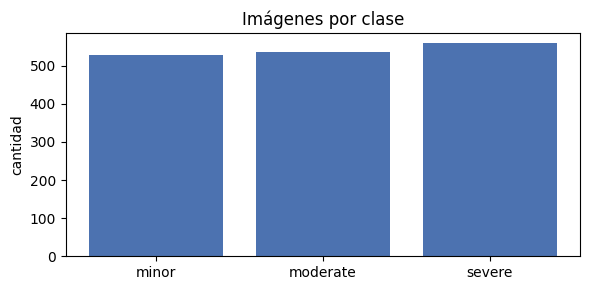

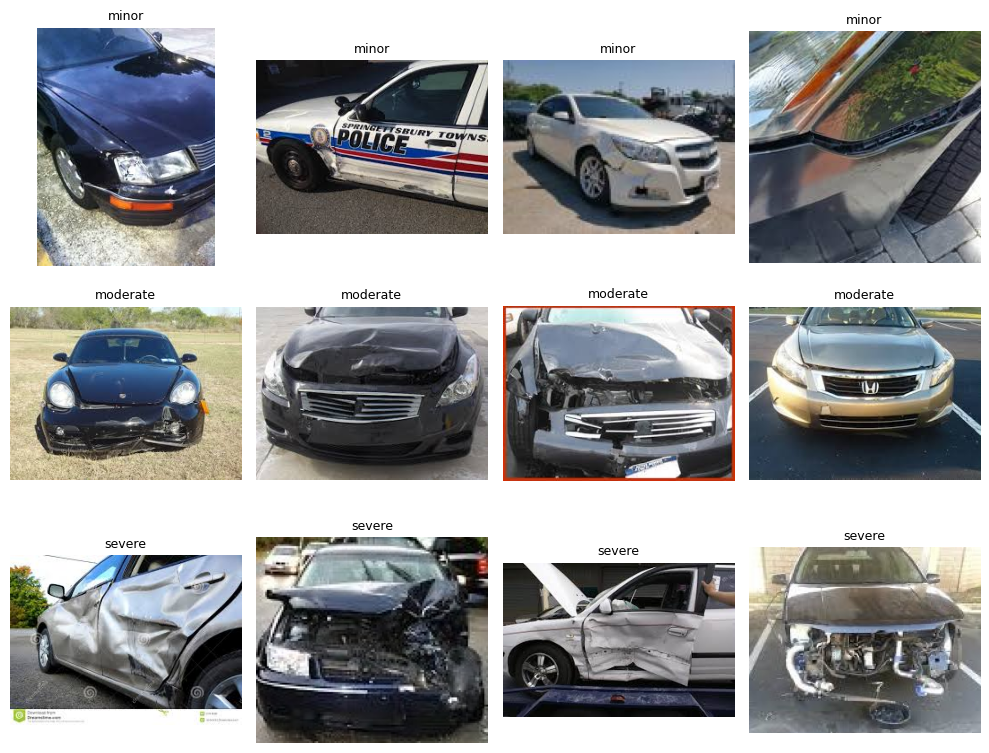

In [ ]:
CLASES = sorted(conteo)
clase_a_id = {c: i for i, c in enumerate(CLASES)}
y_total = np.array([clase_a_id[e] for e in etiquetas])
print("Clases:", CLASES)

plt.figure(figsize=(6, 3))
plt.bar(CLASES, [conteo[c] for c in CLASES], color="#4C72B0")
plt.title("Imágenes por clase"); plt.ylabel("cantidad"); plt.tight_layout(); plt.show()

# Muestra de imágenes
fig, axs = plt.subplots(len(CLASES), 4, figsize=(10, 2.6 * len(CLASES)))
axs = np.atleast_2d(axs)
for i, c in enumerate(CLASES):
    idx = [j for j, e in enumerate(etiquetas) if e == c]
    for k, j in enumerate(random.sample(idx, min(4, len(idx)))):
        axs[i, k].imshow(Image.open(rutas[j]).convert("RGB")); axs[i, k].axis("off")
        axs[i, k].set_title(c, fontsize=9)
    for k in range(min(4, len(idx)), 4):
        axs[i, k].axis("off")
plt.tight_layout(); plt.show()

## 2a. Características de las imágenes digitales



Forma (alto, ancho, canales): (217, 233, 3) | tipo: uint8 | rango: 0 a 255
Esquina superior izquierda, canal rojo (3x3 píxeles):
[[181 181 181]
 [181 181 181]
 [184 184 184]]


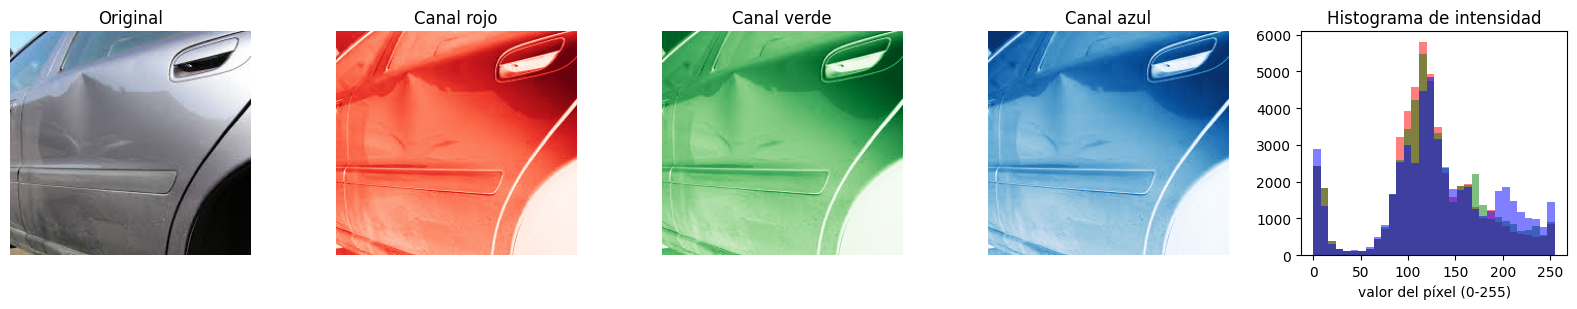

In [ ]:

ejemplo = np.asarray(Image.open(rutas[0]).convert("RGB"))
print("Forma (alto, ancho, canales):", ejemplo.shape, "| tipo:", ejemplo.dtype, "| rango:", ejemplo.min(), "a", ejemplo.max())
print("Esquina superior izquierda, canal rojo (3x3 píxeles):")
print(ejemplo[:3, :3, 0])

fig, axs = plt.subplots(1, 5, figsize=(16, 3.2))
axs[0].imshow(ejemplo); axs[0].set_title("Original"); axs[0].axis("off")
for k, (nombre, color) in enumerate([("Rojo", "Reds"), ("Verde", "Greens"), ("Azul", "Blues")]):
    axs[k + 1].imshow(ejemplo[:, :, k], cmap=color); axs[k + 1].set_title(f"Canal {nombre.lower()}"); axs[k + 1].axis("off")
for k, color in enumerate(["red", "green", "blue"]):
    axs[4].hist(ejemplo[:, :, k].ravel(), bins=32, color=color, alpha=.5)
axs[4].set_title("Histograma de intensidad"); axs[4].set_xlabel("valor del píxel (0-255)")
plt.tight_layout(); plt.show()

Ancho: mín 89, mediana 259, máx 420 px
Alto:  mín 72, mediana 184, máx 306 px
Imágenes más pequeñas que 224 px en algún lado: 98%


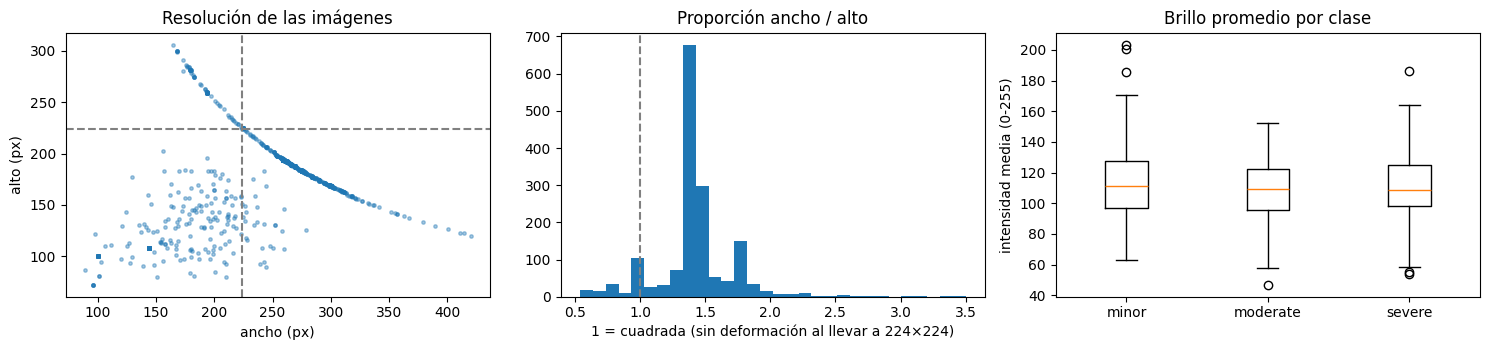

In [ ]:

tamanos = np.array([Image.open(r).size for r in rutas])  # (ancho, alto)
anchos, altos = tamanos[:, 0], tamanos[:, 1]
proporcion = anchos / altos
print(f"Ancho: mín {anchos.min()}, mediana {int(np.median(anchos))}, máx {anchos.max()} px")
print(f"Alto:  mín {altos.min()}, mediana {int(np.median(altos))}, máx {altos.max()} px")
print(f"Imágenes más pequeñas que 224 px en algún lado: {np.mean((anchos < 224) | (altos < 224)):.0%}")

# Brillo promedio por clase
brillo = {c: [] for c in CLASES}
for c in CLASES:
    for r in [r for r, e in zip(rutas, etiquetas) if e == c][:150]:
        brillo[c].append(np.asarray(Image.open(r).convert("L").resize((64, 64))).mean())

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
axs[0].scatter(anchos, altos, s=6, alpha=.4); axs[0].axhline(224, color="gray", ls="--"); axs[0].axvline(224, color="gray", ls="--")
axs[0].set_title("Resolución de las imágenes"); axs[0].set_xlabel("ancho (px)"); axs[0].set_ylabel("alto (px)")
axs[1].hist(proporcion, bins=30); axs[1].axvline(1, color="gray", ls="--")
axs[1].set_title("Proporción ancho / alto"); axs[1].set_xlabel("1 = cuadrada (sin deformación al llevar a 224×224)")
axs[2].boxplot([brillo[c] for c in CLASES]); axs[2].set_xticks(range(1, len(CLASES) + 1), CLASES)
axs[2].set_title("Brillo promedio por clase"); axs[2].set_ylabel("intensidad media (0-255)")
plt.tight_layout(); plt.show()

## 2b. (Opcional) Sumar casos revisados por liquidadores


In [ ]:
MAPEO_SEVERIDAD = {"leve": "minor", "moderado": "moderate", "grave": "severe"}
extra_rutas, extra_y = [], []

if USAR_CASOS_REVISADOS:
    import csv
    from google.colab import files
    subido = files.upload()
    destino = pathlib.Path("/content/casos_revisados")
    with zipfile.ZipFile(next(iter(subido))) as z:
        z.extractall(destino)
    filas = list(csv.DictReader(open(destino / "entrenamiento.csv", encoding="utf-8-sig")))
    sin_foto = repetidas = 0
    for f in filas:
        sev = f["severidad_liquidador"]
        clase = MAPEO_SEVERIDAD.get(sev, sev) if MAPEO_SEVERIDAD.get(sev, sev) in clase_a_id else sev
        foto = next(iter((destino / "fotos" / sev).glob(f["id"] + ".*")), None)
        if foto is None or clase not in clase_a_id:
            sin_foto += 1
            continue
        h = hashlib.md5(foto.read_bytes()).hexdigest()
        if h in vistos:  # misma foto que ya está en el dataset
            repetidas += 1
            continue
        vistos.add(h)
        extra_rutas.append(str(foto)); extra_y.append(clase_a_id[clase])
    print(f"Casos revisados: {len(filas)} | agregados: {len(extra_rutas)} | sin foto o clase: {sin_foto} | repetidos: {repetidas}")
    print("Por clase:", {CLASES[k]: v for k, v in sorted(Counter(extra_y).items())})
    if len(filas):
        acuerdo = sum(f["severidad_modelo"] == f["severidad_liquidador"] for f in filas) / len(filas)
        print(f"Acuerdo modelo-liquidador en estos casos: {acuerdo:.0%}")
else:
    print("Reentrenamiento solo con el dataset base (USAR_CASOS_REVISADOS = False)")

Reentrenamiento solo con el dataset base (USAR_CASOS_REVISADOS = False)


## 3. División entrenamiento / validación / prueba (70 / 15 / 15)


In [ ]:
X_train, X_tmp, y_train, y_tmp = train_test_split(rutas, y_total, test_size=0.30, stratify=y_total, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
if extra_rutas:  # los casos revisados solo entran a entrenamiento
    X_train = list(X_train) + extra_rutas
    y_train = np.concatenate([y_train, np.array(extra_y, dtype=y_train.dtype)])
    print(f"+ {len(extra_rutas)} casos revisados agregados al entrenamiento")
print(f"train={len(X_train)}  val={len(X_val)}  test={len(X_test)}")

# Pesos por clase
pesos_clase = {i: len(y_train) / (len(CLASES) * np.sum(y_train == i)) for i in range(len(CLASES))}
print("Pesos por clase:", {CLASES[i]: round(w, 2) for i, w in pesos_clase.items()})

train=1134  val=243  test=243
Pesos por clase: {'minor': np.float64(1.02), 'moderate': np.float64(1.01), 'severe': np.float64(0.97)}


## 4. Pipeline de datos y *data augmentation*



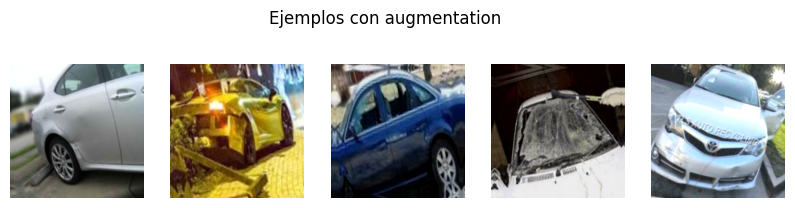

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def cargar(ruta, etiqueta):
    img = tf.io.read_file(ruta)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.clip_by_value(img, 0.0, 255.0)
    return img, etiqueta

augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
], name="augmentation")

def crear_ds(X, y, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if entrenamiento:
        ds = ds.shuffle(len(X), seed=SEED)
    ds = ds.map(cargar, num_parallel_calls=AUTOTUNE)
    if entrenamiento:
        ds = ds.map(lambda x, t: (tf.clip_by_value(augment(x, training=True), 0.0, 255.0), t), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

ds_train = crear_ds(X_train, y_train, entrenamiento=True)
ds_val = crear_ds(X_val, y_val)
ds_test = crear_ds(X_test, y_test)


lote, _ = next(iter(ds_train))
plt.figure(figsize=(10, 2.5))
for i in range(min(5, lote.shape[0])):
    plt.subplot(1, 5, i + 1); plt.imshow(lote[i].numpy().astype("uint8")); plt.axis("off")
plt.suptitle("Ejemplos con augmentation"); plt.show()

## 5. Modelo: EfficientNetB0 + cabeza de clasificación


In [ ]:
base = keras.applications.EfficientNetB0(include_top=False, weights=PESOS, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

entrada = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="imagen")
x = base(entrada, training=False)  # training=False mantiene fijas las estadísticas de BatchNorm
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(len(CLASES), activation="softmax", name="severidad")(x)
model = keras.Model(entrada, salida, name="evaluador_danos")
model.summary(show_trainable=True)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "evaluador_danos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ imagen (InputLayer)         │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ severidad (Dense)           │ (None, 3)             │      3,843 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 6. Fase 1 – entrenar solo la cabeza

In [ ]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]
hist1 = model.fit(ds_train, validation_data=ds_val, epochs=EPOCAS_FASE1,
                  class_weight=pesos_clase, callbacks=callbacks)

Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.4568 - loss: 1.0499 - val_accuracy: 0.4156 - val_loss: 0.9942 - learning_rate: 0.0010
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 17s 486ms/step - accuracy: 0.5961 - loss: 0.8564 - val_accuracy: 0.4815 - val_loss: 0.9311 - learning_rate: 0.0010
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 17s 468ms/step - accuracy: 0.6429 - loss: 0.7801 - val_accuracy: 0.5267 - val_loss: 0.8926 - learning_rate: 0.0010
Epoch 4/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 16s 347ms/step - accuracy: 0.6631 - loss: 0.7714 - val_accuracy: 0.5514 - val_loss: 0.8561 - learning_rate: 0.0010
Epoch 5/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 20s 345ms/step - accuracy: 0.6649 - loss: 0.7353 - val_accuracy: 0.5556 - val_loss: 0.8678 - learning_rate: 0.0010
Epoch 6/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 347ms/step - accuracy: 0.6720 - loss: 0.7336 - val_accuracy: 0.5514 - val_loss: 0.8655 - learning_rate: 0.0010
Epoch 7/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 348ms/step - accuracy: 0.6905 - loss: 0.702

## 7. Fase 2 – *fine-tuning*


In [ ]:
base.trainable = True
for capa in base.layers[:-CAPAS_A_DESCONGELAR]:
    capa.trainable = False
for capa in base.layers:
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False

model.compile(optimizer=keras.optimizers.Adam(5e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks_ft = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]
hist2 = model.fit(ds_train, validation_data=ds_val, epochs=EPOCAS_FASE2,
                  class_weight=pesos_clase, callbacks=callbacks_ft)

Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 63s 995ms/step - accuracy: 0.7090 - loss: 0.6489 - val_accuracy: 0.5967 - val_loss: 0.8140 - learning_rate: 5.0000e-05
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 371ms/step - accuracy: 0.7284 - loss: 0.6263 - val_accuracy: 0.5967 - val_loss: 0.8136 - learning_rate: 5.0000e-05
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 358ms/step - accuracy: 0.7487 - loss: 0.5801 - val_accuracy: 0.6173 - val_loss: 0.8320 - learning_rate: 5.0000e-05
Epoch 4/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 21s 361ms/step - accuracy: 0.7654 - loss: 0.5560 - val_accuracy: 0.6049 - val_loss: 0.8192 - learning_rate: 5.0000e-05
Epoch 5/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 20s 361ms/step - accuracy: 0.7831 - loss: 0.5188 - val_accuracy: 0.6049 - val_loss: 0.8128 - learning_rate: 2.5000e-05
Epoch 6/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 363ms/step - accuracy: 0.7831 - loss: 0.5106 - val_accuracy: 0.6049 - val_loss: 0.8205 - learning_rate: 2.5000e-05
Epoch 7/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 360ms/step - acc

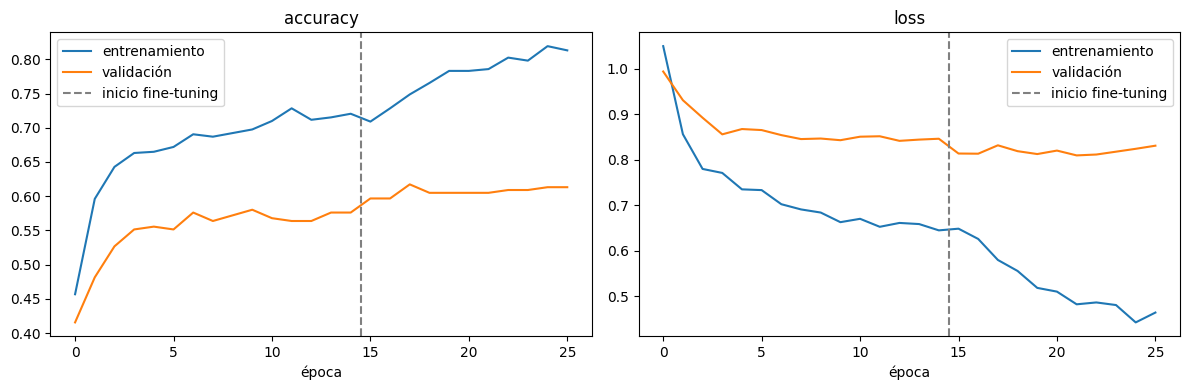

In [ ]:
def unir(h1, h2, k):
    return h1.history[k] + h2.history[k]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip(axs, ["accuracy", "loss"]):
    ax.plot(unir(hist1, hist2, k), label="entrenamiento")
    ax.plot(unir(hist1, hist2, "val_" + k), label="validación")
    ax.axvline(len(hist1.history[k]) - 0.5, color="gray", ls="--", label="inicio fine-tuning")
    ax.set_title(k); ax.set_xlabel("época"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Evaluación en el conjunto de prueba


Accuracy test: 0.720   |   F1 macro: 0.718

              precision    recall  f1-score   support

       minor      0.750     0.759     0.755        79
    moderate      0.618     0.580     0.599        81
      severe      0.782     0.819     0.800        83

    accuracy                          0.720       243
   macro avg      0.717     0.720     0.718       243
weighted avg      0.717     0.720     0.718       243



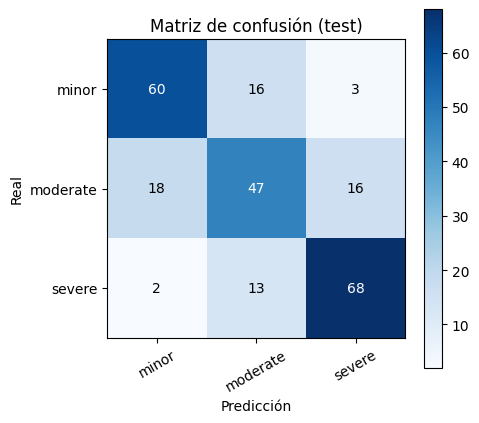

In [ ]:
prob_test = model.predict(ds_test, verbose=0)
pred_test = prob_test.argmax(axis=1)
acc = (pred_test == y_test).mean()
f1m = f1_score(y_test, pred_test, average="macro")
print(f"Accuracy test: {acc:.3f}   |   F1 macro: {f1m:.3f}\n")
print(classification_report(y_test, pred_test, target_names=CLASES, digits=3))

cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASES)), CLASES, rotation=30); ax.set_yticks(range(len(CLASES)), CLASES)
for i in range(len(CLASES)):
    for j in range(len(CLASES)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusión (test)")
plt.colorbar(im); plt.tight_layout(); plt.show()

68 errores de 243


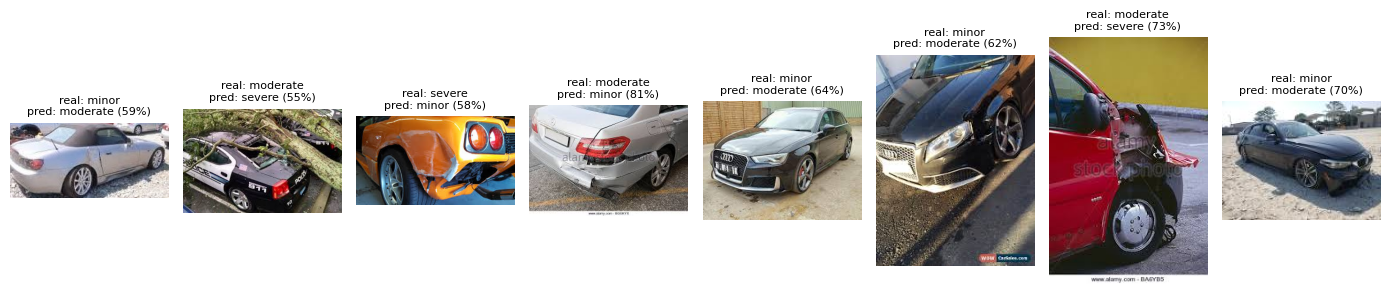

confianza ≥ 50%: cubre 95% de los casos con accuracy 73.0%
confianza ≥ 60%: cubre 77% de los casos con accuracy 78.6%
confianza ≥ 70%: cubre 62% de los casos con accuracy 80.8%
confianza ≥ 80%: cubre 45% de los casos con accuracy 87.2%


In [ ]:

errores = np.where(pred_test != y_test)[0]
print(f"{len(errores)} errores de {len(y_test)}")
muestra = errores[:8]
plt.figure(figsize=(14, 4))
for k, i in enumerate(muestra):
    plt.subplot(1, len(muestra), k + 1)
    plt.imshow(Image.open(X_test[i]).convert("RGB")); plt.axis("off")
    plt.title(f"real: {CLASES[y_test[i]]}\npred: {CLASES[pred_test[i]]} ({prob_test[i].max():.0%})", fontsize=8)
plt.tight_layout(); plt.show()

conf = prob_test.max(axis=1)
for umbral in [0.5, 0.6, 0.7, 0.8]:
    m = conf >= umbral
    if m.sum():
        print(f"confianza ≥ {umbral:.0%}: cubre {m.mean():.0%} de los casos con accuracy {(pred_test[m] == y_test[m]).mean():.1%}")

## 9. Exportar el modelo para AWS


In [ ]:
model.save("modelo_danos.keras")
model.export("saved_model_danos")

conv = tf.lite.TFLiteConverter.from_saved_model("saved_model_danos")
conv.optimizations = [tf.lite.Optimize.DEFAULT]
with open("modelo_danos.tflite", "wb") as f:
    f.write(conv.convert())

with open("etiquetas.json", "w") as f:
    json.dump({"clases": CLASES, "img_size": IMG_SIZE, "version": VERSION_MODELO, "casos_revisados": len(extra_rutas),
               "metricas_test": {"accuracy": round(float(acc), 4), "f1_macro": round(float(f1m), 4)}},
              f, ensure_ascii=False, indent=2)
print("Tamaño .tflite: %.1f MB" % (os.path.getsize("modelo_danos.tflite") / 1e6))

Saved artifact at 'saved_model_danos'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='imagen')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  135250530895248: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  135250530895824: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  135251606880720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135251606881488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135251606881296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135251606882256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135251606881680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135251606882640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135251679000912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135251678998416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

In [ ]:
# Verificación: el .tflite debe coincidir con el modelo de Keras
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    !pip -q install ai-edge-litert
    from ai_edge_litert.interpreter import Interpreter

interp = Interpreter(model_path="modelo_danos.tflite")
interp.allocate_tensors()
ent, sal = interp.get_input_details()[0], interp.get_output_details()[0]
coinciden = 0
n = min(50, len(X_test))
for i in range(n):
    img, _ = cargar(X_test[i], 0)
    interp.set_tensor(ent["index"], img.numpy()[None].astype(np.float32))
    interp.invoke()
    coinciden += int(interp.get_tensor(sal["index"]).argmax() == pred_test[i])
print(f"Coincidencia TFLite vs Keras: {coinciden}/{n}")

Coincidencia TFLite vs Keras: 48/50


In [ ]:
# Descargar los archivos que van al servidor
with zipfile.ZipFile("modelo_para_aws.zip", "w") as z:
    z.write("modelo_danos.tflite"); z.write("etiquetas.json")
from google.colab import files
files.download("modelo_para_aws.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Comparación: CNN propia con convolución y pooling


In [ ]:
def crear_cnn_propia():
    entrada = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1 / 255)(entrada)                     # normaliza los píxeles a 0-1
    for filtros in [32, 64, 128, 128]:                          # 4 bloques convolución + pooling
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)                            # 224 → 112 → 56 → 28 → 14

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(len(CLASES), activation="softmax")(x)
    return keras.Model(entrada, salida, name="cnn_propia")

cnn = crear_cnn_propia()
cnn.summary()
cnn.compile(optimizer=keras.optimizers.Adam(5e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

import time
t0 = time.time()
hist_cnn = cnn.fit(ds_train, validation_data=ds_val, epochs=EPOCAS_CNN_PROPIA, class_weight=pesos_clase, verbose=2,
                   callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
                              keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)])
tiempo_cnn = time.time() - t0

Model: "cnn_propia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 249,283 (973.76 KB)

 Trainable params: 249,283 (973.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
36/36 - 41s - 1s/step - accuracy: 0.3395 - loss: 1.0999 - val_accuracy: 0.3457 - val_loss: 1.1002 - learning_rate: 5.0000e-04
Epoch 2/25
36/36 - 14s - 377ms/step - accuracy: 0.3642 - loss: 1.0934 - val_accuracy: 0.3621 - val_loss: 1.0717 - learning_rate: 5.0000e-04
Epoch 3/25
36/36 - 14s - 378ms/step - accuracy: 0.4118 - loss: 1.0712 - val_accuracy: 0.4774 - val_loss: 1.0289 - learning_rate: 5.0000e-04
Epoch 4/25
36/36 - 14s - 380ms/step - accuracy: 0.4347 - loss: 1.0493 - val_accuracy: 0.4691 - val_loss: 1.0113 - learning_rate: 5.0000e-04
Epoch 5/25
36/36 - 20s - 564ms/step - accuracy: 0.4568 - loss: 1.0284 - val_accuracy: 0.5350 - val_loss: 0.9949 - learning_rate: 5.0000e-04
Epoch 6/25
36/36 - 21s - 572ms/step - accuracy: 0.4630 - loss: 1.0357 - val_accuracy: 0.5021 - val_loss: 1.0137 - learning_rate: 5.0000e-04
Epoch 7/25
36/36 - 14s - 400ms/step - accuracy: 0.4956 - loss: 1.0034 - val_accuracy: 0.5226 - val_loss: 1.0026 - learning_rate: 5.0000e-04
Epoch 8/25
36/36 - 14s 

              precision    recall  f1-score   support

       minor      0.667     0.608     0.636        79
    moderate      0.524     0.407     0.458        81
      severe      0.528     0.687     0.597        83

    accuracy                          0.568       243
   macro avg      0.573     0.567     0.564       243
weighted avg      0.572     0.568     0.563       243

Predicciones por clase: {'minor': 72, 'moderate': 63, 'severe': 108}
Modelo                                Parámetros  Capas conv  Accuracy  F1 macro
CNN propia (desde cero)                  249,283           4     0.568     0.564
EfficientNetB0 + transfer learning     4,053,414          81     0.720     0.718
Tiempo de entrenamiento de la CNN propia: 6.4 min


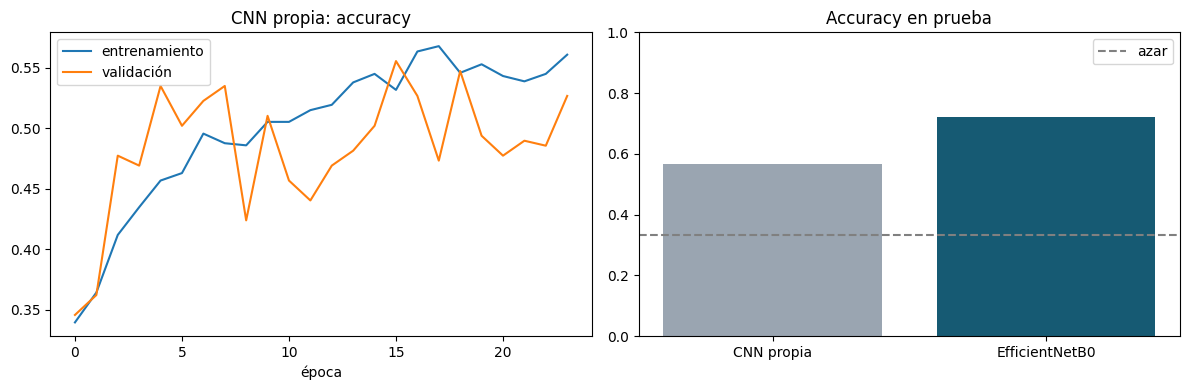

In [ ]:
pred_cnn = cnn.predict(ds_test, verbose=0).argmax(axis=1)
acc_cnn, f1_cnn = (pred_cnn == y_test).mean(), f1_score(y_test, pred_cnn, average="macro")
print(classification_report(y_test, pred_cnn, target_names=CLASES, digits=3, zero_division=0))
print("Predicciones por clase:", {CLASES[k]: int(v) for k, v in zip(*np.unique(pred_cnn, return_counts=True))})

capas = lambda m: sum(isinstance(l, (layers.Conv2D, layers.DepthwiseConv2D)) for l in m.layers)
tabla = [
    ("CNN propia (desde cero)", cnn.count_params(), capas(cnn), acc_cnn, f1_cnn),
    ("EfficientNetB0 + transfer learning", model.count_params(), capas(base), acc, f1m),
]
print(f"{'Modelo':<36}{'Parámetros':>12}{'Capas conv':>12}{'Accuracy':>10}{'F1 macro':>10}")
for nombre, params, nconv, a_, f_ in tabla:
    print(f"{nombre:<36}{params:>12,}{nconv:>12}{a_:>10.3f}{f_:>10.3f}")
print(f"Tiempo de entrenamiento de la CNN propia: {tiempo_cnn / 60:.1f} min")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(hist_cnn.history["accuracy"], label="entrenamiento"); axs[0].plot(hist_cnn.history["val_accuracy"], label="validación")
axs[0].set_title("CNN propia: accuracy"); axs[0].set_xlabel("época"); axs[0].legend()
axs[1].bar([t[0].split(" (")[0].split(" +")[0] for t in tabla], [t[3] for t in tabla], color=["#9aa5b1", "#165a73"])
axs[1].set_ylim(0, 1); axs[1].set_title("Accuracy en prueba"); axs[1].axhline(1 / len(CLASES), color="gray", ls="--", label="azar")
axs[1].legend(); plt.tight_layout(); plt.show()

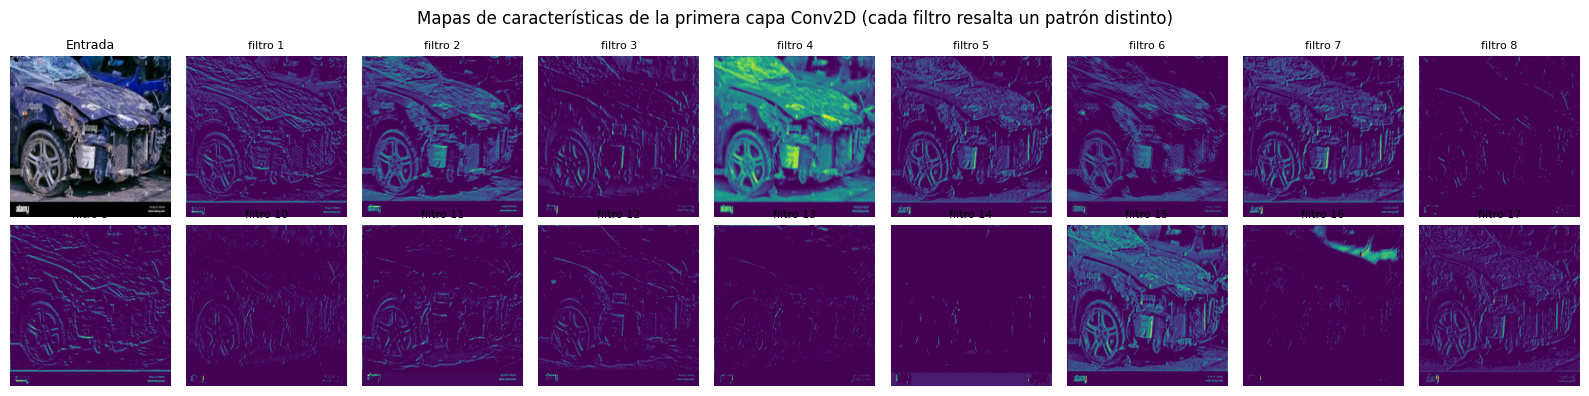

In [ ]:

primera_conv = next(l for l in cnn.layers if isinstance(l, layers.Conv2D))
extractor = keras.Model(cnn.input, primera_conv.output)
img, _ = cargar(X_test[0], 0)
mapas = extractor.predict(img[None], verbose=0)[0]

fig, axs = plt.subplots(2, 9, figsize=(16, 4))
axs[0, 0].imshow(img.numpy().astype("uint8")); axs[0, 0].set_title("Entrada", fontsize=9)
for k, ax in enumerate(axs.ravel()):
    ax.axis("off")
    if k > 0 and k - 1 < mapas.shape[-1]:
        ax.imshow(mapas[:, :, k - 1], cmap="viridis"); ax.set_title(f"filtro {k}", fontsize=8)
plt.suptitle("Mapas de características de la primera capa Conv2D (cada filtro resalta un patrón distinto)")
plt.tight_layout(); plt.show()

## 11. (Opcional) Probar con una foto propia

In [ ]:
from google.colab import files
for nombre in files.upload():
    img, _ = cargar(nombre, 0)
    p = model.predict(img[None], verbose=0)[0]
    plt.imshow(img.numpy().astype("uint8")); plt.axis("off")
    plt.title(" | ".join(f"{c}: {v:.0%}" for c, v in zip(CLASES, p))); plt.show()

KeyboardInterrupt: 